# PySCENIC analysis

## Prepare input data

In [1]:
import scanpy as sc
import scanpy.external as sce

import anndata
from pathlib import Path
from tqdm import tqdm
import pandas as pd

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


In [3]:
from scipy import stats

In [4]:
import scipy.sparse as sp
import anndata as ad

In [5]:
import json

# import dask.dataframe as dd
import numpy as np
import pandas as pd
#import relation_data_lake as rdl
import scanpy as sc
import scipy.sparse as sp
from anndata import AnnData
#from relation_data_lake.aws.aws_api import pull_folder

In [6]:
sc.set_figure_params(scanpy=True, dpi=80, dpi_save=400, figsize = [1.5*6.4, 1.5*4.8])
sns.set_style("whitegrid")

In [7]:
import loompy as lp
import json
import zlib
import glob
import base64

In [8]:
from pyscenic.rss import regulon_specificity_scores
from pyscenic.plotting import plot_rss
import matplotlib.pyplot as plt
from adjustText import adjust_text
import seaborn as sns
from pyscenic.binarization import binarize

In [9]:
adata = sc.read_h5ad('../../data_generated/Rd13_Data_post_filtering_cell_types-reseq.h5ad.gzip')

In [11]:
adata.write_loom('Rd13_Data_post_filtering_cell_types-reseq.loom', write_obsm_varm=True )

In [ ]:
# create basic row and column attributes for the loom file:
row_attrs = {
    "Gene": np.array(adata.var_names)
}
col_attrs = {
    "CellID": np.array(adata.obs_names),
    "nGene": np.array( np.sum(adata.X.transpose()>0 , axis=0)).flatten(),
    "nUMI": np.array( np.sum(adata.X.transpose() , axis=0)).flatten()
}
lp.create(f_loom_path_scenic, adata.X.transpose(), row_attrs, col_attrs)

## Run PySCENIC

Download auxiliary datasets [as described](https://pyscenic.readthedocs.io/en/latest/installation.html#auxiliary-datasets) to the folder `database`:

- allTFs_mm.txt
- mm10_10kbp_up_10kbp_down_full_tx_v10_clust.genes_vs_motifs.rankings.feather
- mm10_10kbp_up_10kbp_down_full_tx_v10_clust.genes_vs_motifs.scores.feather
- mm10_500bp_up_100bp_down_full_tx_v10_clust.genes_vs_motifs.rankings.feather
- mm10_500bp_up_100bp_down_full_tx_v10_clust.genes_vs_motifs.scores.feather
- motifs-v10nr_clust-nr.mgi-m0.001-o0.0.tbl

Prepare the singularity container:

```bash
apptainer build aertslab-pyscenic-0.12.1.sif docker://aertslab/pyscenic:0.12.1
```

Use the following runscripts:

```bash
# (1) run_pyscenic_grn.sh
BASE_DIR=/vscratch/wes/cf

singularity run \
  -B $BASE_DIR:$BASE_DIR \
  aertslab-pyscenic-0.12.1.sif pyscenic grn \
    $BASE_DIR/Rd13_Data_post_filtering_cell_types-reseq.loom \
    $BASE_DIR/database/allTFs_mm.txt \
    -o $BASE_DIR/output/adjnew.csv \
    --num_workers 8

# (2) run_pyscenic_ctx.sh
BASE_DIR=/vscratch/wes/cf

singularity run \
  -B $BASE_DIR:$BASE_DIR \
  aertslab-pyscenic-0.12.1.sif pyscenic ctx \
    $BASE_DIR/output/adjnew.csv \
    `ls $BASE_DIR/database/*feather` \
    --annotations_fname $BASE_DIR/database/motifs-v10nr_clust-nr.mgi-m0.001-o0.0.tbl \
    --expression_mtx_fname $BASE_DIR/Rd13_Data_post_filtering_cell_types-reseq.loom \
    --output $BASE_DIR/output/reg.csv \
    --mask_dropouts \
    --num_workers 8

# (3) run_pyscenic_aucell.sh
BASE_DIR=/vscratch/wes/cf

singularity run \
  -B $BASE_DIR:$BASE_DIR \
  aertslab-pyscenic-0.12.1.sif pyscenic aucell \
    $BASE_DIR/Rd13_Data_post_filtering_cell_types-reseq.loom \
    $BASE_DIR/output/reg.csv \
    --output $BASE_DIR/output/pyscenic_output.loom \
    --num_workers 16
```


## Analyze results

In [10]:
# scenic output
lf = lp.connect("../../data_generated/pyscenic/pyscenic_output.loom", mode='r', validate=False )
meta = json.loads(zlib.decompress(base64.b64decode( lf.attrs.MetaData )))
exprMat = pd.DataFrame( lf[:,:], index=lf.ra.Gene, columns=lf.ca.CellID).T
auc_mtx = pd.DataFrame( lf.ca.RegulonsAUC, index=lf.ca.CellID)

In [11]:
auc_mtx
# auc_mtx.to_csv("auc_mtx.csv")

,Atf1(+),Atf2(+),Atf4(+),Atf7(+),Bach1(+),Bcl6b(+),Bclaf1(+),Bhlhe40(+),Bhlhe41(+),Bptf(+),...,Ybx1(+),Yy1(+),Zbtb20(+),Zbtb44(+),Zbtb7a(+),Zfp148(+),Zfp37(+),Zfp639(+),Zfp652(+),Zfx(+)
AAACCCAAGCTTGTGT-Rep5-Resting,0.000000,0.0,0.015115,0.001228,0.003749,0.009470,0.005238,0.0,0.000000,0.006389,...,0.051061,0.013045,0.009529,0.000000,0.004220,0.002177,0.014460,0.001881,0.008224,0.000000
AAACCCACACATGAAA-Rep5-Resting,0.000000,0.0,0.023084,0.000810,0.000291,0.000000,0.004984,0.0,0.000000,0.007745,...,0.053270,0.010117,0.012169,0.000000,0.006330,0.003289,0.008827,0.000000,0.011065,0.000000
AAACCCACATCGCTGG-Rep5-Resting,0.000000,0.0,0.017146,0.000000,0.000253,0.018308,0.003960,0.0,0.000000,0.003392,...,0.052033,0.013018,0.008369,0.000000,0.001628,0.002332,0.008531,0.001347,0.004785,0.000000
AAACGAAAGTTCAACC-Rep5-Resting,0.000000,0.0,0.017045,0.000261,0.010616,0.021149,0.006701,0.0,0.000000,0.006106,...,0.048258,0.015426,0.011139,0.003627,0.001758,0.002352,0.012945,0.000788,0.004187,0.006396
AAACGAACAAAGACTA-Rep5-Resting,0.001166,0.0,0.016286,0.001019,0.000233,0.000000,0.004057,0.0,0.000000,0.004636,...,0.052854,0.014703,0.007957,0.000000,0.003567,0.002986,0.010903,0.001220,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTAGTCGTTAAGCAA-1-Quiescent_OP1L_NM_NA_Rep2_LaraMouseFibroblastReseq2023,0.000000,0.0,0.014246,0.000000,0.000223,0.007260,0.002980,0.0,0.000000,0.005088,...,0.055215,0.014822,0.007713,0.000000,0.002944,0.001941,0.008037,0.000000,0.000000,0.000000
TTTCACATCTTGGAAC-1-Quiescent_OP1L_NM_NA_Rep2_LaraMouseFibroblastReseq2023,0.000000,0.0,0.014566,0.000000,0.004371,0.023201,0.004850,0.0,0.000914,0.005710,...,0.050884,0.013954,0.007927,0.000000,0.000573,0.001611,0.012088,0.000000,0.000050,0.000000
TTTCCTCGTTCGTAAC-1-Quiescent_OP1L_NM_NA_Rep2_LaraMouseFibroblastReseq2023,0.000000,0.0,0.013001,0.000914,0.003846,0.000000,0.004800,0.0,0.000000,0.000000,...,0.052942,0.015236,0.005173,0.000000,0.001015,0.001645,0.009552,0.000000,0.000199,0.000000
TTTGGAGTCAGCGCGT-1-Quiescent_OP1L_NM_NA_Rep2_LaraMouseFibroblastReseq2023,0.000000,0.0,0.012379,0.000000,0.000000,0.016730,0.001907,0.0,0.000000,0.000057,...,0.052626,0.014240,0.004669,0.000000,0.000000,0.000755,0.007345,0.000000,0.000000,0.000000


In [12]:
np.float = float
rss_cellType = regulon_specificity_scores(auc_mtx, adata.obs.cell_type)
rss_cellType.to_csv("../../data_generated/python_figure_data/S3_data.csv")
rss_cellType

,Atf1(+),Atf2(+),Atf4(+),Atf7(+),Bach1(+),Bcl6b(+),Bclaf1(+),Bhlhe40(+),Bhlhe41(+),Bptf(+),...,Ybx1(+),Yy1(+),Zbtb20(+),Zbtb44(+),Zbtb7a(+),Zfp148(+),Zfp37(+),Zfp639(+),Zfp652(+),Zfx(+)
Inflammatory (injury response),0.262748,0.167445,0.306761,0.302108,0.304559,0.288557,0.317978,0.176456,0.173002,0.340392,...,0.296742,0.297886,0.312936,0.231571,0.348161,0.312287,0.329543,0.215685,0.299646,0.220161
Proliferative,0.192040,0.167445,0.239216,0.238222,0.209822,0.205864,0.235526,0.172666,0.168737,0.230956,...,0.235038,0.226534,0.231016,0.200554,0.223349,0.228650,0.230750,0.202473,0.218647,0.181489
Deactivated myofibroblasts,0.249690,0.167445,0.250157,0.241603,0.261985,0.217374,0.251010,0.193360,0.315809,0.239041,...,0.250484,0.251480,0.244939,0.241321,0.234441,0.248476,0.249004,0.261670,0.200922,0.239151
Quiescent,0.265371,0.167445,0.334558,0.256482,0.373467,0.348704,0.350655,0.179930,0.190117,0.318981,...,0.345397,0.356905,0.341976,0.309380,0.315411,0.336581,0.335653,0.253638,0.331468,0.246218
Lamp1-fibroblasts,0.262284,0.167445,0.222117,0.199434,0.219498,0.201283,0.224160,0.185723,0.190126,0.214625,...,0.224085,0.233607,0.217264,0.244907,0.214207,0.230430,0.222860,0.263504,0.192534,0.245784
Tissue-repair,0.232621,0.167445,0.212680,0.254559,0.243648,0.202171,0.221239,0.173560,0.191337,0.201587,...,0.210826,0.212227,0.211883,0.236359,0.216088,0.212577,0.219281,0.212040,0.215606,0.206627
Transitory,0.217434,0.167445,0.311313,0.216111,0.277715,0.315272,0.308791,0.180188,0.176728,0.280436,...,0.322639,0.322455,0.314215,0.246605,0.287478,0.307665,0.303025,0.236077,0.315542,0.202575
Stress-fiber fibroblasts,0.184340,0.167445,0.232327,0.186706,0.200644,0.215616,0.224146,0.172232,0.171695,0.214978,...,0.230765,0.226394,0.232953,0.189533,0.228303,0.231844,0.225229,0.203689,0.231881,0.182719
Inflammatory & fibrotic,0.189727,0.167445,0.267843,0.230934,0.239958,0.234496,0.265297,0.175937,0.168554,0.279275,...,0.261519,0.256141,0.272201,0.192435,0.273313,0.274194,0.274586,0.197536,0.272351,0.190477
Myofibroblasts,0.227086,0.168035,0.330343,0.223503,0.275642,0.267766,0.301857,0.190709,0.296243,0.259945,...,0.330043,0.320807,0.319153,0.218893,0.294733,0.300359,0.309858,0.293823,0.256492,0.206752


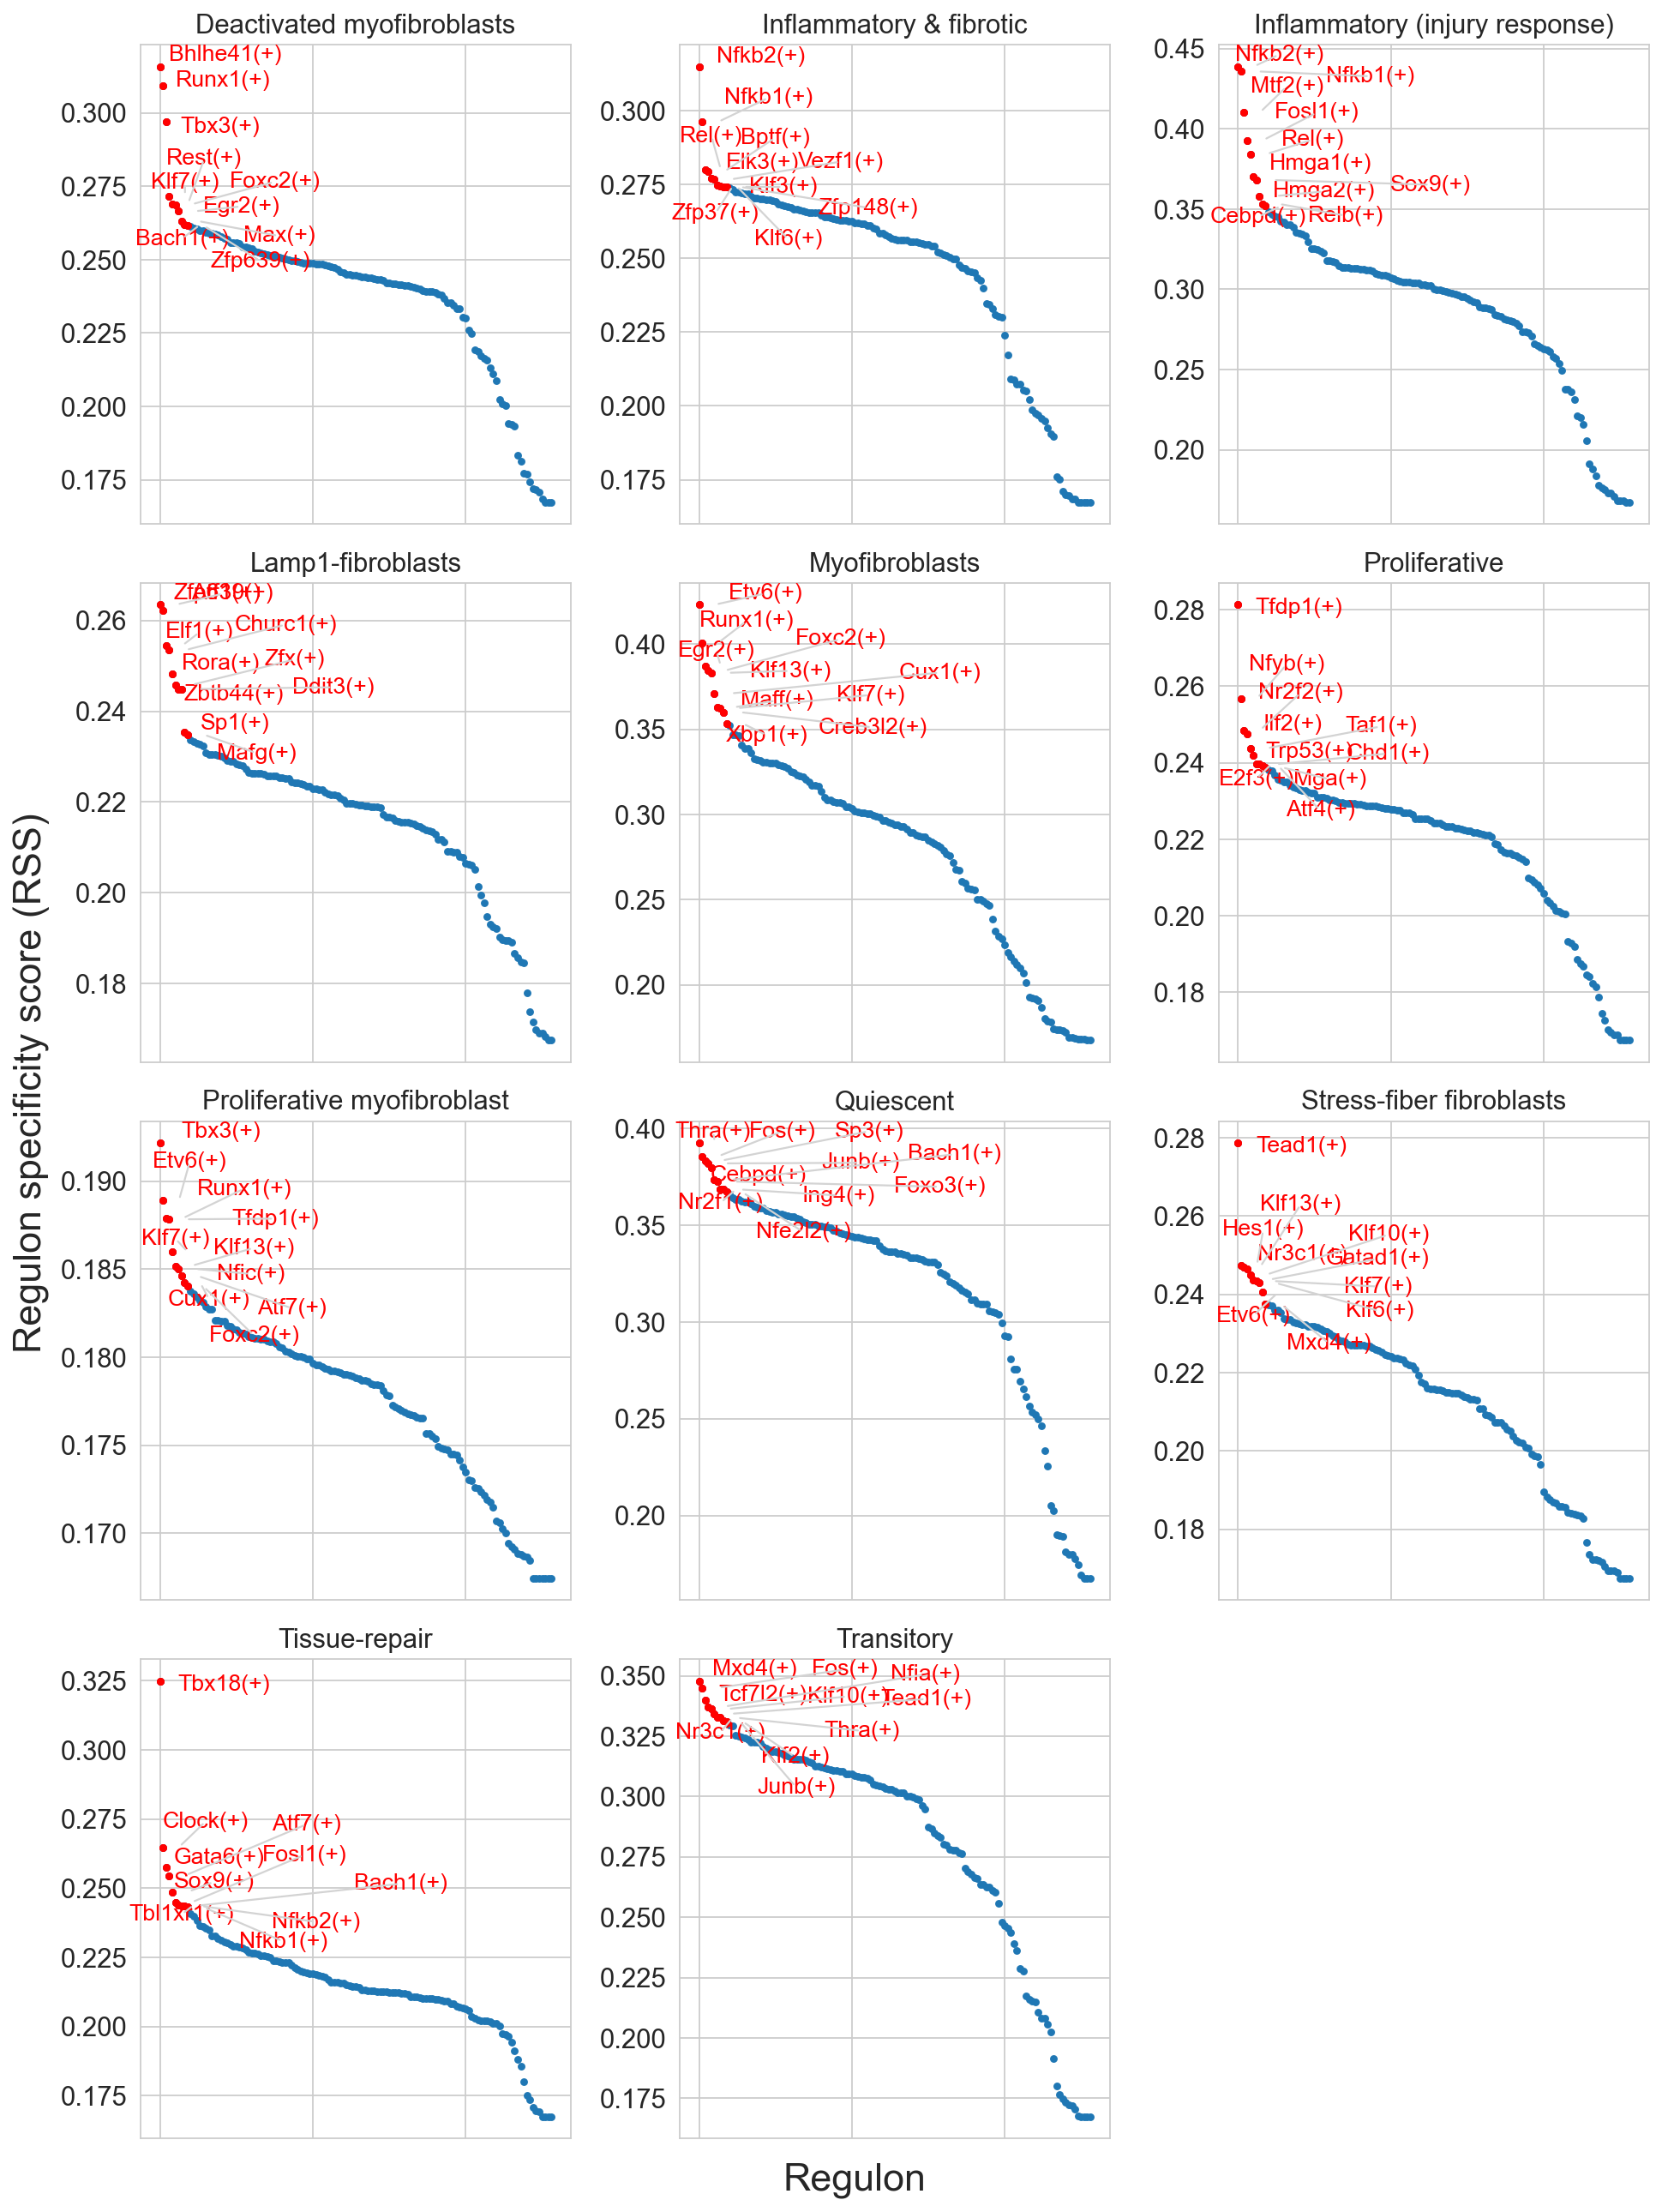

In [ ]:
cats = sorted(list(set(adata.obs.cell_type )))

fig = plt.figure(figsize=(12, 16))
for c, num in zip(cats, range(1, len(cats)+1)):
    x = rss_cellType.T[c]
    ax = fig.add_subplot(4, 3, num)
    plot_rss(rss_cellType, c, top_n=10, max_n=None, ax=ax)
    ax.set_ylim( x.min()-(x.max()-x.min())*0.05 , x.max()+(x.max()-x.min())*0.05 )
    for t in ax.texts:
        t.set_fontsize(12)
    ax.set_ylabel('')
    ax.set_xlabel('')
    adjust_text(ax.texts, autoalign='xy', ha='right', va='bottom', arrowprops=dict(arrowstyle='-',color='lightgrey'), precision=0.001 )

fig.text(0.5, 0.0, 'Regulon', ha='center', va='center', size='x-large')
fig.text(0.00, 0.5, 'Regulon specificity score (RSS)', ha='center', va='center', rotation='vertical', size='x-large')
plt.tight_layout()
plt.rcParams.update({'figure.autolayout': True, 'figure.titlesize': 'medium' ,'axes.labelsize': 'medium','axes.titlesize':'medium','xtick.labelsize':'medium','ytick.labelsize':'medium'})
plt.savefig("figures/Fibroblast_perturb-seq_cellType-RSS-top10.pdf", dpi=600, bbox_inches = "tight")
plt.savefig("figures/Fibroblast_perturb-seq_cellType-RSS-top10.png", dpi=600, bbox_inches = "tight")
plt.savefig("figures/Fibroblast_perturb-seq_cellType-RSS-top10.svg", dpi=600, bbox_inches = "tight")

plt.show()

<Axes: ylabel='Count'>

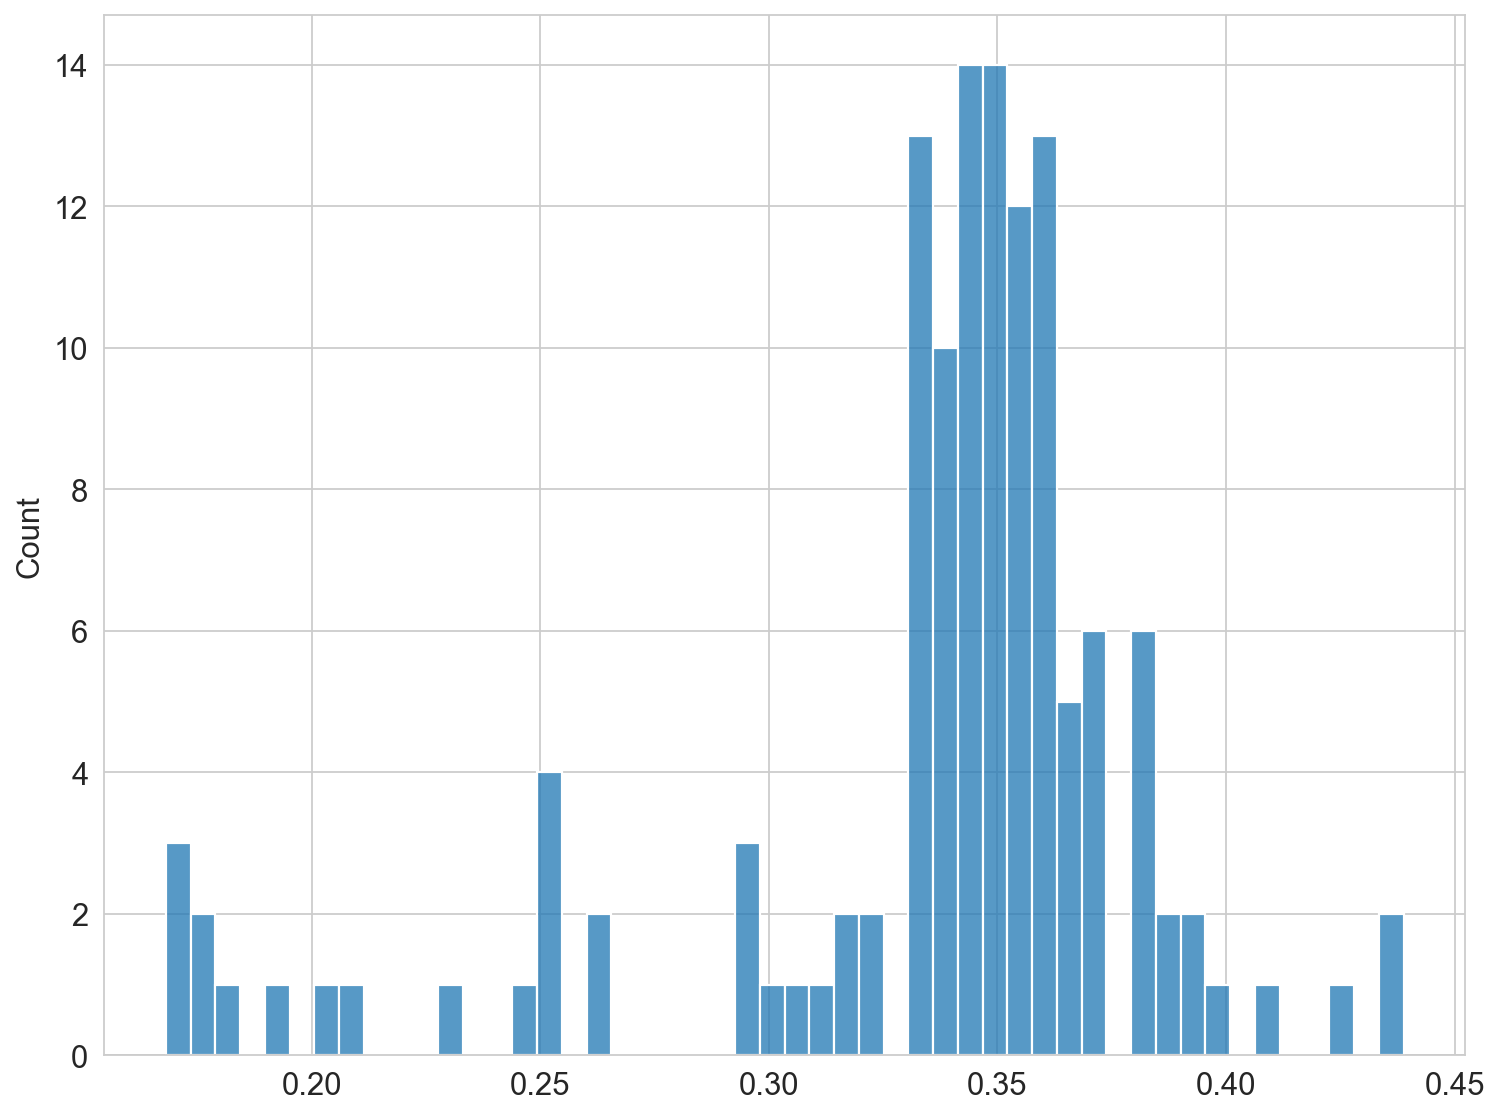

In [19]:
sns.histplot(rss_cellType.max(), bins = 50)

In [20]:
rss_cellType.drop(columns=rss_cellType.columns[rss_cellType.isna().any()], inplace=True)

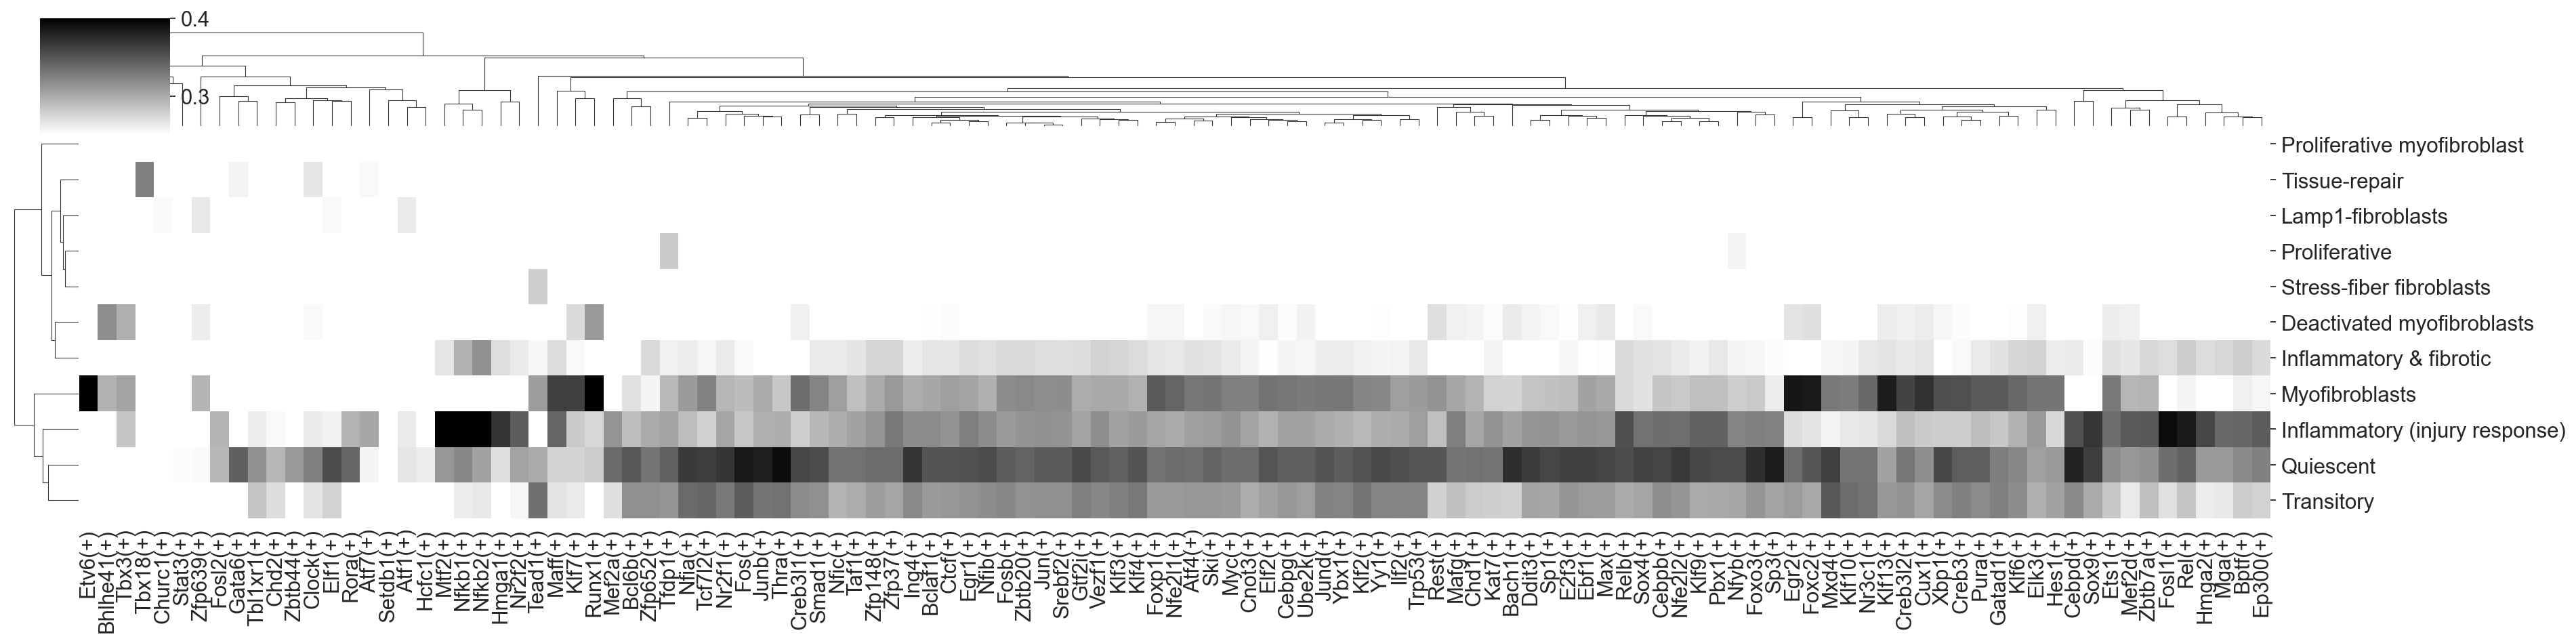

In [ ]:
#sns.clustermap(rss_cellType)

g = sns.clustermap(rss_cellType.drop(columns = rss_cellType.columns[rss_cellType.max() < 0.25]),
               #row_linkage=row_linkage_df,
               #col_linkage=col_linkage_df,
               figsize=(24, 6),
               cmap="binary",
               row_cluster = True,
               col_cluster = True,
               #metric='ward',
               vmin = 0.25, vmax = 0.4,
               dendrogram_ratio=[0.03, 0.2],
               xticklabels =1, yticklabels=1,
               #linewidth=0.1, linecolor='w',
              )
#ax.hlines([3, 6, 9], *ax.get_xlim())
#g.cax.set_visible(False)
#g.ax_row_dendrogram.set_visible(False)
#g.ax_col_dendrogram.set_visible(False)

plt.savefig("figures/clustermap_RSS1.pdf", dpi=600, bbox_inches = "tight")
plt.savefig("figures/clustermap_RSS1.svg", dpi=600, bbox_inches = "tight")
plt.savefig("figures/clustermap_RSS1.png", dpi=600, bbox_inches = "tight")